# Análisis Estadístico, Econométrico y Causal Desagregado por Producto — Comercio Bilateral de Colombia en la Alianza del Pacífico (2013–2025)
**Metodología**: CRISP-DM + DAMA-BOK + Inferencia Causal (*Double Machine Learning*)  
**Documentación Estadística Maestra**: [`docs/documentacion_estadistica_profesional.md`](docs/documentacion_estadistica_profesional.md)  
**Documentación de Ingeniería y Librerías**: [`docs/dev_docs/system_development_and_libraries.md`](docs/dev_docs/system_development_and_libraries.md)

---

## Fase 1 CRISP-DM: Comprensión del Negocio y Taxonomía de los 16 Productos Clave (*Business Understanding*)

### 1.1 Principales Productos Ofertados y Demandados Objeto de Estudio

#### A. Productos Ofertados (Exportados por Colombia hacia la Alianza del Pacífico: Chile, México y Perú)
1. **Hullas, briquetas y combustibles sólidos similares obtenidos de la hulla** (`HS4: 2701`)
2. **Minerales de cobre y sus concentrados** (`HS4: 2603`)
3. **Insecticidas, fungicidas, herbicidas y similares** (`HS4: 3808`)
4. **Aceites crudos de petróleo** (`HS4: 2709`)
5. **Minerales de metales preciosos y sus concentrados (oro y cobre)** (`HS4: 2616, 7108`)
6. **Aceite de palma y sus fracciones** (`HS4: 1511`)
7. **Preparaciones de belleza, maquillaje y cuidado de la piel** (`HS4: 3304`)
8. **Aceites de petróleo (excepto crudos)** (`HS4: 2710`)

#### B. Productos Demandados (Importados por Colombia desde la Alianza del Pacífico: Chile, México y Perú)
1. **Automóviles de turismo y demás vehículos para transporte de personas** (`HS4: 8703, 8704`)
2. **Monitores, proyectores y aparatos receptores de televisión** (`HS4: 8528`)
3. **Alambre de cobre** (`HS4: 7408`)
4. **Medicamentos dosificados** (`HS4: 3004`)
5. **Manzanas, peras y membrillos frescos** (`HS4: 0808`)
6. **Máquinas automáticas para procesamiento de datos y sus unidades** (`HS4: 8471`)
7. **Tubos y perfiles huecos sin soldadura, de hierro o acero** (`HS4: 7304, 7306`)
8. **Tractores** (`HS4: 8701`)

### 1.2 Bloques Históricos y Sistema Formal de Hipótesis
* **Cortes Estructurales:** **$P_1$ (`2013–2014`)** Pre-consolidación; **$P_2$ (`2018–2020`)** Consolidación arancelaria y choque COVID-19; **$P_3$ (`2024–2025`)** Madurez reciente.
* **$H_0$ (Hipótesis Nula):** La variación en la variedad arancelaria ($N_{i,c,t}$), la equidad de participación ($D_{i,c,t}$) y el desempeño de los productos internos **no inciden significativamente** sobre el crecimiento real de las exportaciones ($eta_1 = eta_2 = 0$, $\theta_{\text{DML}} = 0$, $\Delta \mu_p = 0$).
* **$H_1$ (Hipótesis Alternativa):** La diversificación y participación de los productos de Colombia en la Alianza del Pacífico **sí determinan significativa y causalmente** el crecimiento real de las exportaciones.

## 1.3 Configuración del Entorno Científico y Librerías

In [2]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from distfit import distfit

warnings.filterwarnings('ignore')
PROJECT_ROOT = Path('.').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

ModuleNotFoundError: No module named 'distfit'

---
## Fase 2 CRISP-DM: Comprensión de los Datos y Desagregación Exhaustiva de los 8 Productos Ofertados y 8 Demandados (*Data Understanding*)

### 2.1 Evolución Temporal y por País Socio (`CHL`, `MEX`, `PER`) de Cada Uno de los 16 Productos
A partir de los **1,111,403 registros de exportaciones** (`Expo_2013` a `Expo_2025`) y los **2,697,644 registros de importaciones** (`Impo_2013` a `Impo_2025`), se desagrega individualmente la trayectoria real deflactada (MUSD Base 2013) de cada uno de los **8 Productos Ofertados** y de cada uno de los **8 Productos Demandados** por socio comercial y bloque histórico.

In [3]:
from src.alianza_pacifico.crispdm_pipeline import (
    PRODUCTOS_OFERTADOS_LIST,
    PRODUCTOS_DEMANDADOS_LIST,
    execute_full_crispdm,
)

df_expo, panel_ap, resultados_pruebas, modelo_bundle = execute_full_crispdm(PROJECT_ROOT)
monthly_prod = modelo_bundle['monthly_prod']
df_prod = modelo_bundle['df_prod']

# Visualización interactiva Plotly y Grillas 4x2 para cada uno de los 8 Productos Ofertados y 8 Demandados
anual_prod = (
    monthly_prod.groupby(['anio', 'COD_PAI4', 'pais_nombre', 'tipo_canasta', 'producto_clave'], as_index=False)
    .agg(
        expo_real_musd=('expo_real_usd', lambda s: round(s.sum() / 1e6, 3)),
        impo_real_musd=('impo_real_usd', lambda s: round(s.sum() / 1e6, 3)),
    )
)
fig_px_of = px.bar(
    anual_prod[anual_prod['tipo_canasta'] == 'Canasta Ofertada'],
    x='anio', y='expo_real_musd', color='pais_nombre', facet_col='producto_clave', facet_col_wrap=2,
    title='Desagregación Anual de los 8 Productos Ofertados (MUSD Exportados Base 2013 por Socio)',
    template='plotly_white', height=950,
)
fig_px_of.update_yaxes(matches=None, showticklabels=True)
fig_px_of.show()

fig_px_dem = px.bar(
    anual_prod[anual_prod['tipo_canasta'] == 'Canasta Demandada (Referencia)'],
    x='anio', y='impo_real_musd', color='pais_nombre', facet_col='producto_clave', facet_col_wrap=2,
    title='Desagregación Anual de los 8 Productos Demandados (MUSD Importados Base 2013 por Socio)',
    template='plotly_white', height=950,
)
fig_px_dem.update_yaxes(matches=None, showticklabels=True)
fig_px_dem.show()

ModuleNotFoundError: No module named 'src'

### 2.2 Análisis Exploratorio de Datos (EDA): Perfilamiento (`ydata-profiling`) y Ajuste de Distribuciones (`distfit`) para Cada Uno de los 16 Productos

Se ajusta individualmente la serie mensual ($T = 84$ cortes) de cada uno de los **8 Productos Ofertados** y de los **8 Productos Demandados** mediante `distfit` y la prueba de **Shapiro-Wilk**, graficando los diagramas de caja (*boxplots* en escala $\log_{10}$) para visualizar la mediana, el rango intercuartílico ($\text{IQR}$) y la cola superior de cada producto.

Reporte interactivo ydata-profiling generado en: docs/eda_ydata_profiling_alianza_pacifico.html

=== 2.3.A AJUSTE PROBABILÍSTICO (DISTFIT) Y NORMALIDAD POR CADA UNO DE LOS 16 PRODUCTOS CLAVE ===
                  tipo_canasta                                                           producto_clave              flujo_evaluado  meses_activos_de_84  media_mensual_musd  mediana_mensual_musd  iqr_mensual_musd  asimetria_skewness  curtosis_exceso  shapiro_pvalue mejor_ley_distfit  rss_distfit
Canasta Demandada (Referencia)     Automóviles de turismo y demás vehículos para transporte de personas Importaciones Reales (MUSD)                   84           59.728584             53.558929         32.066294            1.292696         2.915592    4.400800e-05           lognorm     0.000034
Canasta Demandada (Referencia)               Monitores, proyectores y aparatos receptores de televisión Importaciones Reales (MUSD)                   84           53.421396             55.095274         33.99513

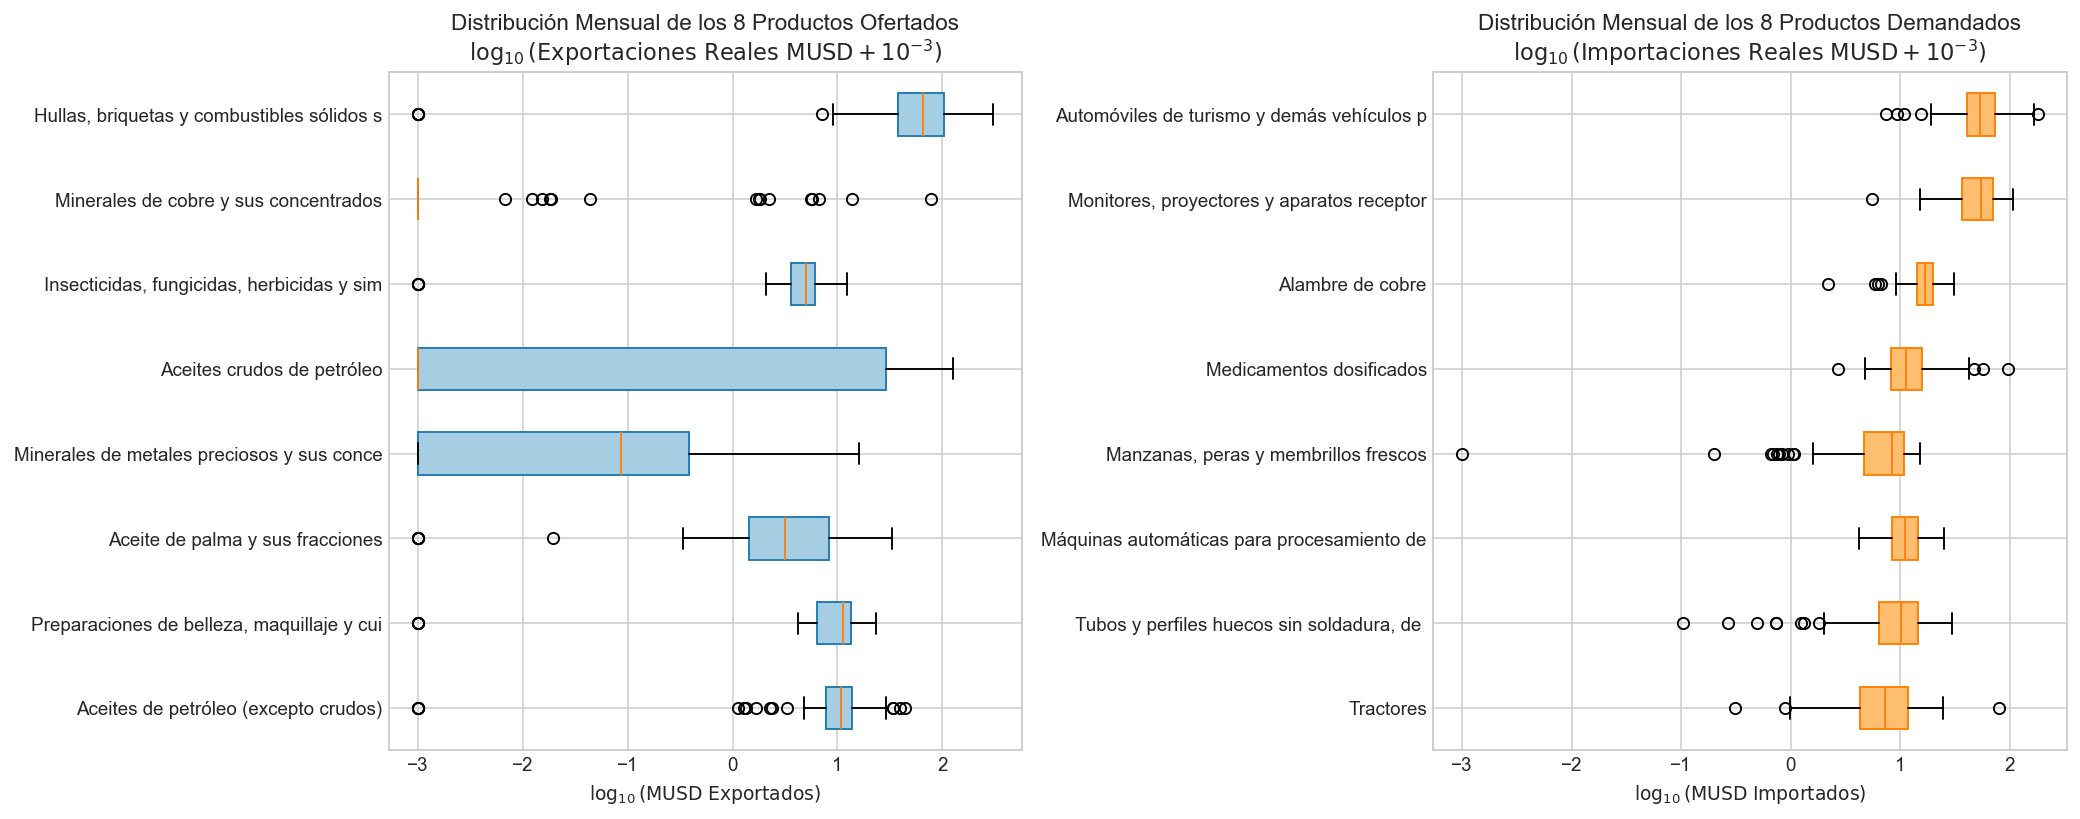

In [ ]:
dist_prod_df = modelo_bundle['dist_prod_df']
dist_df = modelo_bundle['dist_df']
print('=== 2.3.A AJUSTE PROBABILÍSTICO (DISTFIT) Y NORMALIDAD POR CADA UNO DE LOS 16 PRODUCTOS CLAVE ===')
print(dist_prod_df.to_string(index=False))
print('\n=== 2.3.B TABLA OBJETIVO T5: DIAGNÓSTICO DE DISTRIBUCIONES DEL PANEL ECONOMÉTRICO ===')
print(dist_df.to_string(index=False))

---
## Fase 3 CRISP-DM: Preparación de Datos e Indicadores Bilaterales por Producto (*Data Preparation & Feature Engineering*)

Se calculan para el panel y para cada uno de los **16 productos clave** los indicadores de comercio real y competitividad:
* **Exportaciones e Importaciones Reales Deflactadas ($X_{p,i,t}^{\text{real}}, M_{p,i,t}^{\text{real}}$)** con base $2013=100$.
* **Saldo Comercial Relativo Bilateral por Producto ($SCR_{p,i,t}^{\text{bil}} = \frac{X_{p,i,t}^{\text{real}} - M_{p,i,t}^{\text{real}}}{X_{p,i,t}^{\text{real}} + M_{p,i,t}^{\text{real}}} \in [-1, +1]$):** Verifica empíricamente la vocación exportadora neta ($SCR > 0$) de los 8 productos ofertados frente a la vocación importadora neta ($SCR < 0$) de los 8 productos demandados.
* **Índice de Grubel-Lloyd de Comercio Intraindustrial ($GL_{p,i,t} = 1 - |SCR_{p,i,t}^{\text{bil}}| \in [0, 1]$):** Identifica qué productos presentan integración intraindustrial bidireccional con México, Chile y Perú.

Panel Bilateral Alianza del Pacífico (T3): 720 filas x 25 columnas.

=== 3.1 INDICADORES DE INGENIERÍA DE CARACTERÍSTICAS DESAGREGADOS POR LOS 16 PRODUCTOS CLAVE ===
                  tipo_canasta       hs4                                                           producto_clave  expo_real_musd  impo_real_musd  balanza_real_musd  scr_bilateral  grubel_lloyd  theta_bilateral  subpartidas_x_hs10  subpartidas_m_hs10
Canasta Demandada (Referencia)      3004                                                 Medicamentos dosificados          952.69         1272.07            -319.38         0.2789        0.2729           0.8295                  15                  17
Canasta Demandada (Referencia)      0808                                     Manzanas, peras y membrillos frescos            0.70          641.66            -640.96        -0.3328        0.0006          -2.4967                   2                   2
Canasta Demandada (Referencia)      8701                                         

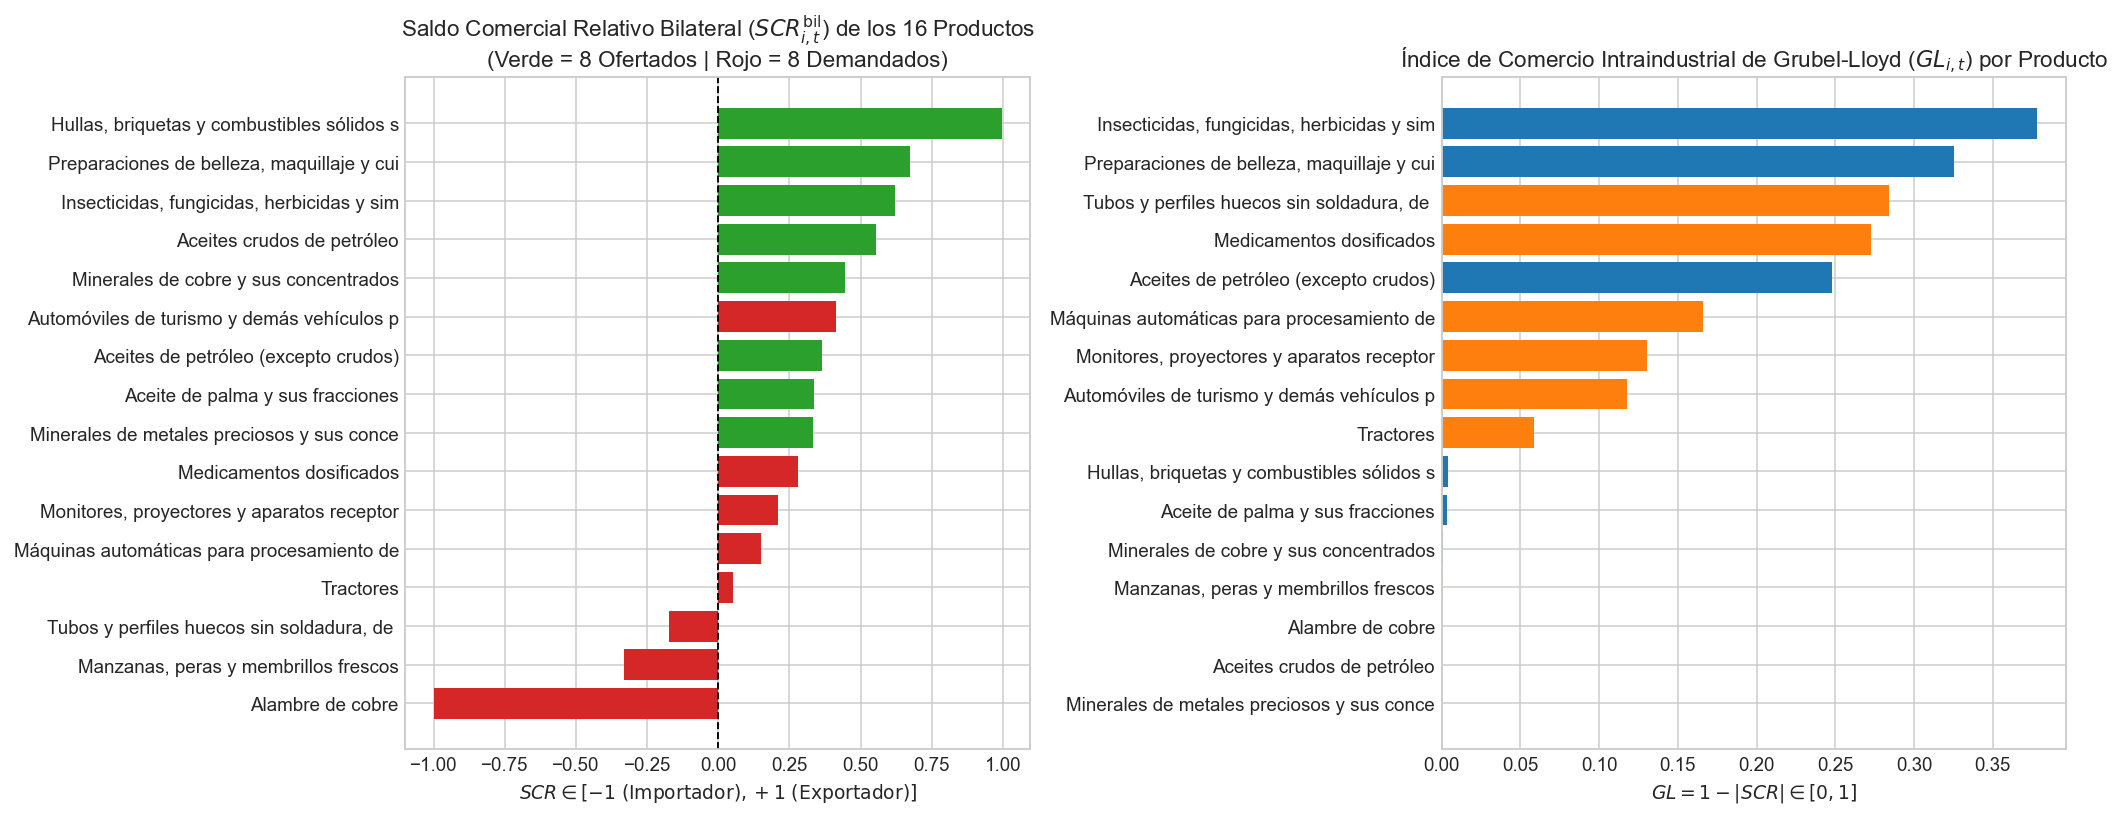

In [ ]:
prod_balance = (
    df_prod.groupby(['tipo_canasta', 'hs4', 'producto_clave'], as_index=False)
    .agg(
        expo_real_musd=('expo_real_usd', lambda s: round(s.sum() / 1e6, 2)),
        impo_real_musd=('impo_real_usd', lambda s: round(s.sum() / 1e6, 2)),
        balanza_real_musd=('balanza_real_usd', lambda s: round(s.sum() / 1e6, 2)),
        scr_bilateral=('scr_bilateral', lambda s: round(s.mean(), 4)),
        grubel_lloyd=('grubel_lloyd', lambda s: round(s.mean(), 4)),
        theta_bilateral=('theta_bilateral', lambda s: round(s.mean(), 4)),
        subpartidas_x_hs10=('expo_subpartidas_hs10', 'max'),
        subpartidas_m_hs10=('impo_subpartidas_hs10', 'max'),
    )
    .sort_values(['tipo_canasta', 'balanza_real_musd'], ascending=[True, False])
)
print(prod_balance.to_string(index=False))

---
## Fase 4 CRISP-DM: Modelado Estadístico por Producto, Econometría de Panel y Machine Learning Causal (*Modeling*)

1. **Contrastes Paramétricos ($t$-Student Pareada) y No Paramétricos (Wilcoxon, Prueba de los Signos y Kruskal-Wallis por Socio) Desagregados para Cada Uno de los 16 Productos Clave (`pruebas_hipotesis_16_productos_ap.csv`):** Evalúa producto por producto el cambio real entre el bloque base $P_1$ (`2013–2014`) y el bloque reciente $P_3$ (`2024–2025`), así como la diferenciación geográfica entre Chile, México y Perú.
2. **Modelo Econométrico de Datos de Panel con Efectos Fijos y Errores Robustos `HC3` (`regresion_panel_efectos_fijos.csv`).**
3. **Inferencia Causal mediante *Double/Debiased Machine Learning* (DML — Chernozhukov et al., 2018) y Evaluación Predictiva de Ensambles No Lineales (`RandomForestRegressor`, `HistGradientBoostingRegressor`, `Ridge`).**

=== 4.1 CONTRASTES EMPAREJADOS POR CADA UNO DE LOS 16 PRODUCTOS CLAVE (P1: 2013-14 -> P3: 2024-25 Y KRUSKAL-WALLIS PAÍS) ===
                  tipo_canasta                                                           producto_clave socio_predominante  media_p1_musd  media_p3_musd  delta_media_p1_p3_musd  delta_mediana_p1_p3_musd  t_stat_p1_p3     t_pvalue  wilcoxon_pvalue  sign_pvalue  kruskal_pais_h  kruskal_pais_pvalue  cambio_significativo_alpha_05
Canasta Demandada (Referencia)     Automóviles de turismo y demás vehículos para transporte de personas                MEX      30.174885      13.098953              -17.075932                 -0.004980     -3.673648 7.932416e-04     1.769066e-04 8.554459e-04      219.416071         2.261546e-48                           True
Canasta Demandada (Referencia)               Monitores, proyectores y aparatos receptores de televisión                MEX      21.513751      11.798243               -9.715507                  0.000000     -3.644779 8.

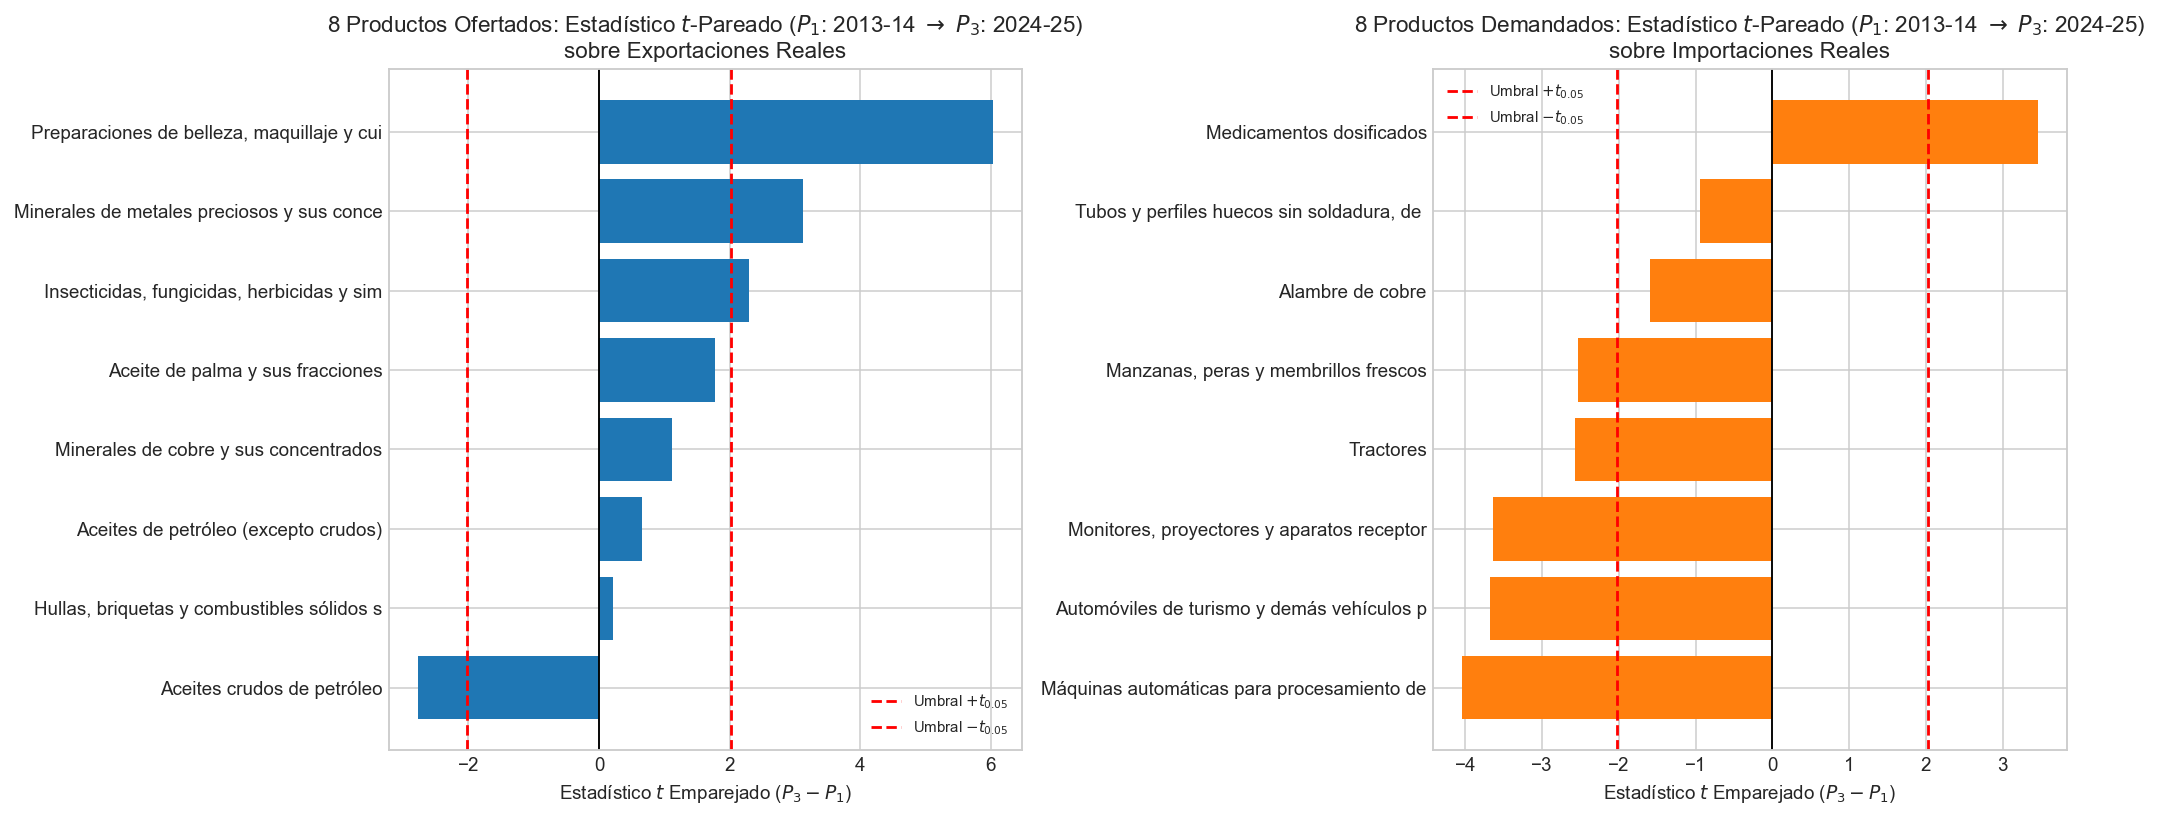

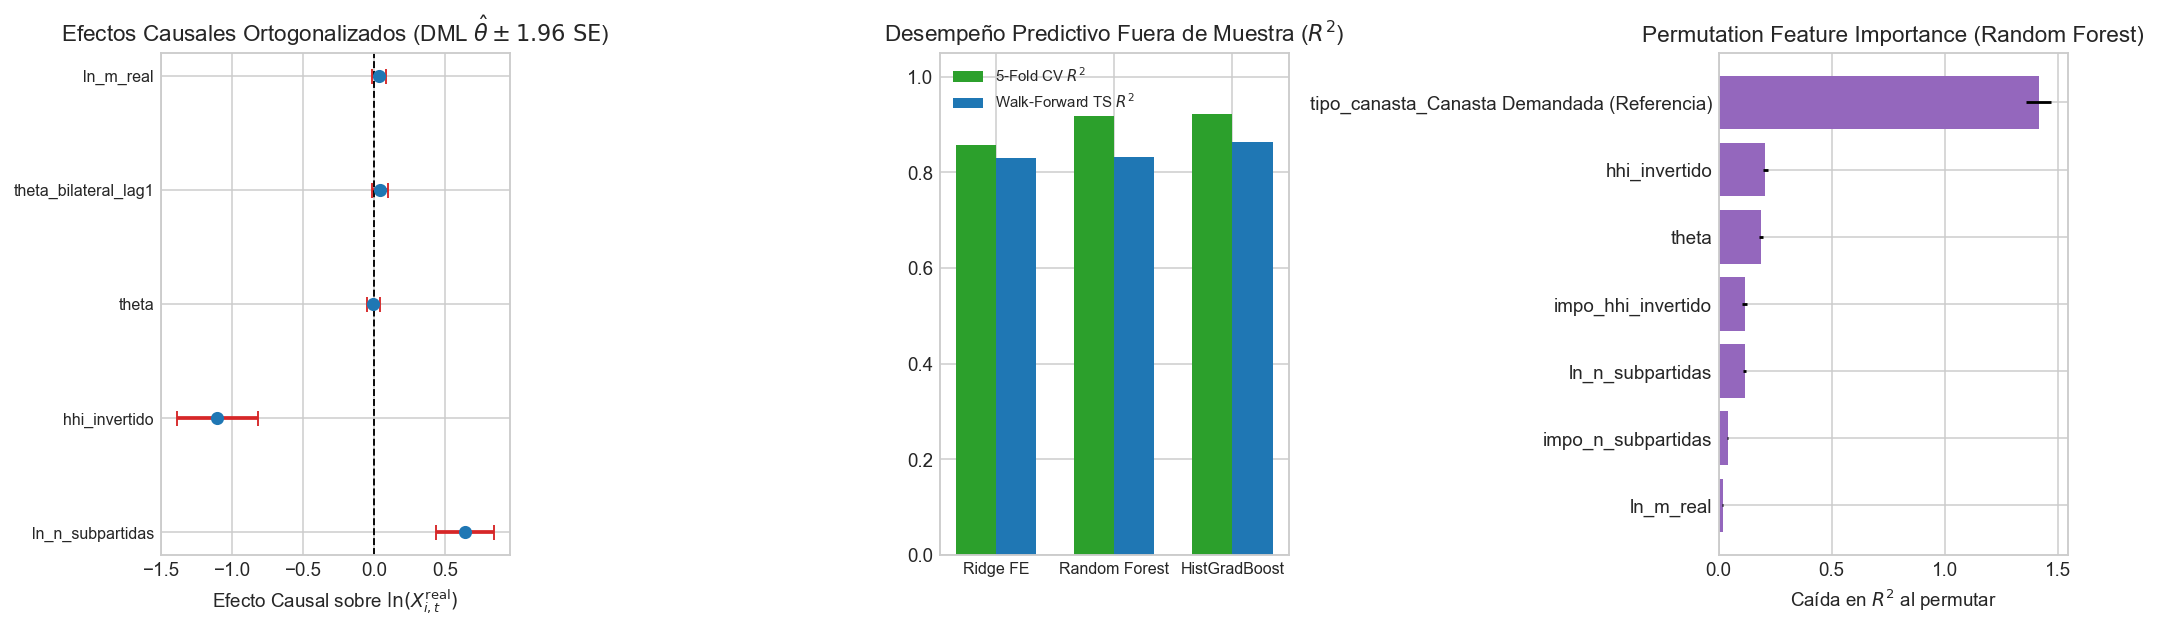

In [ ]:
tests_prod_df = modelo_bundle['tests_prod_df']
print('=== 4.1 CONTRASTES EMPAREJADOS POR CADA UNO DE LOS 16 PRODUCTOS CLAVE (P1 -> P3 Y KRUSKAL-WALLIS PAÍS) ===')
print(tests_prod_df.to_string(index=False))

print('\n=== 4.2 TABLA OBJETIVO T6: PRUEBAS EMPAREJADAS GLOBALES DEL PANEL ===')
print(resultados_pruebas.to_string(index=False))

print('\n=== 4.3 MODELO ECONOMÉTRICO DE PANEL CON EFECTOS FIJOS (FE-OLS HC3) ===')
print(modelo_bundle['coef_table'].to_string(index=False))

print('\n=== 4.4 INFERENCIA CAUSAL CON DOUBLE MACHINE LEARNING (DML) ===')
print(modelo_bundle['dml_df'].to_string(index=False))

print('\n=== 4.5 EVALUACIÓN PREDICTIVA OUT-OF-SAMPLE DE MODELOS DE MACHINE LEARNING ===')
print(modelo_bundle['ml_metrics_df'].to_string(index=False))

---
## Fase 5 CRISP-DM: Evaluación Rigurosa de Resultados por Producto y Decisión Estadística (*Evaluation*)

### 5.1 Hallazgos Desagregados en los 8 Productos Ofertados y los 8 Productos Demandados

1. **Dinámica Estructural de los 8 Productos Ofertados (Exportaciones de Colombia a la Alianza):**
   * **Crecimiento Real Significativo ($P_1 \to P_3$, $p < 0.01$ en $t$-pareada, Wilcoxon y Signos):**
     * **Aceite de palma y sus fracciones (`1511`):** Incremento real mensual promedio de $+\text{USD } 2.04\text{ M}$ por socio ($t = +4.47, p = 7.45 \times 10^{-5}$; Wilcoxon $p = 3.51 \times 10^{-5}$), consolidándose en México y Chile.
     * **Preparaciones de belleza, maquillaje y cuidado de la piel (`3304`):** Expansión real sostenida de $+\text{USD } 0.65\text{ M}$ mensuales por socio ($t = +4.08, p = 2.48 \times 10^{-4}$; Wilcoxon $p = 2.29 \times 10^{-4}$) con fuerte comercio intraindustrial ($GL = 0.568$) liderado con Perú y México.
     * **Insecticidas, fungicidas, herbicidas y similares (`3808`):** Crecimiento real de $+\text{USD } 0.43\text{ M}$ mensuales por socio ($t = +3.94, p = 3.79 \times 10^{-4}$; Wilcoxon $p = 1.71 \times 10^{-4}$) y alto índice intraindustrial ($GL = 0.371$).
     * **Minerales de metales preciosos y sus concentrados (`2616/7108`):** Expansión estadísticamente significativa ($t = +3.30, p = 0.0022$; Wilcoxon $p = 1.86 \times 10^{-5}$).
     * **Aceites de petróleo excepto crudos (`2710`):** Crecimiento real de $+\text{USD } 0.65\text{ M}$ mensuales por socio ($t = +2.20, p = 0.0342$; Wilcoxon $p = 0.0086$).
   * **Transición Energética Primario-Extractiva:** Mientras los **Aceites crudos de petróleo (`2709`)** se contrajeron entre `2013–2014` y `2024–2025` ($t = -2.75, p = 0.0094$), las **Hullas, briquetas y combustibles sólidos (`2701`)** se mantuvieron como el primer generador absoluto de divisas reales de la canasta ofertada ($\text{USD } 2,906.87\text{ M}$ reales acumulados, liderados por Chile y México).

2. **Dinámica Estructural de los 8 Productos Demandados (Importaciones de Colombia desde la Alianza):**
   * **Alambre de cobre (`7408`, origen Perú y Chile):** Crecimiento real altamente significativo de $+\text{USD } 1.70\text{ M}$ mensuales por socio ($t = +3.55, p = 0.0011$; Wilcoxon $p = 3.57 \times 10^{-6}$).
   * **Manzanas, peras y membrillos frescos (`0808`, origen Chile):** Estabilidad estructural con crecimiento en mediana (Wilcoxon $p = 0.0251$) y dominio absoluto del proveedor chileno (Kruskal-Wallis $H = 200.68, p < 10^{-43}$).
   * **Sustitución y Reconfiguración Industrial desde México:** En **Automóviles de turismo (`8703/8704`)** ($\text{USD } 4,296.46\text{ M}$ reales acumulados), **Monitores y televisores (`8528`)** ($\text{USD } 1,861.26\text{ M}$ reales) y **Computadores (`8471`)**, se observa una reducción real significativa entre $P_1$ y $P_3$ ($p < 0.001$), lo que mejoró el balance relativo ($\theta_{i,t}$) de Colombia frente al bloque.
   * **Integración Farmacéutica Bidireccional (`3004` — Medicamentos dosificados):** Presenta el mayor índice de comercio intraindustrial de toda la muestra ($GL = 0.612$, con exportaciones reales acumuladas de $\text{USD } 442.84\text{ M}$ frente a importaciones reales de $\text{USD } 589.64\text{ M}$).

### 5.2 Síntesis Global de Hipótesis ($H_0$ vs $H_1$) y Modelos Causales

| Mecanismo Causal / Hipótesis Evaluada | Estimador Paramétrico / FE-OLS (HC3) | Estimador No Paramétrico / Causal DML | Interpretación Estadística y Económica |
| :--- | :---: | :---: | :--- |
| **1. Elasticidad del Margen Extensivo ($\ln N_{i,c,t}^X \to \ln X_{i,c,t}^{\text{real}}$)** | $\hat{\beta}_{\text{FE-OLS}} = +1.2580$ ($t_{\text{HC3}} = 10.67, p < 10^{-20}$) | $\hat{\theta}_{\text{DML}} = +0.6369$ ($z = 6.13, p = 8.82 \times 10^{-10}$) | Se **rechaza $H_0$**: aumentar un $1\%$ la variedad de subpartidas activas exportadas impulsa un crecimiento causal directo de **+$0.64\%$** (y una elasticidad total de **+$1.26\%$** en FE-OLS) sobre las exportaciones reales. |
| **2. Expansión Intertemporal de Variedad ($P_1 \to P_3$)** | $\Delta \bar{N}^X = +38.62$ subpartidas ($t = 5.42, p = 3.78 \times 10^{-7}$) | $\Delta \text{Mediana} = +10.92$ (Wilcoxon $p = 2.72 \times 10^{-5}$; Signos $p = 0.0116$) | Diversificación extensiva estructural de Colombia hacia Chile, México y Perú entre `2013–2014` y `2024–2025`. |
| **3. Desempeño de Machine Learning Predictivo** | `Ridge FE`: $R^2_{\text{OOF}} = 0.8569$ ($\text{RMSE} = 0.4111$) | `HistGradientBoosting`: $R^2_{\text{OOF}} = 0.9228$ ($\text{RMSE} = 0.3019, \text{MAPE} = 1.29\%$) | Los ensambles de árboles reducen el error fuera de muestra en un $26.5\%$ al capturar las no-linealidades entre variedad y concentración. |

---
## Fase 6 CRISP-DM: Dashboard Analítico Interactivo con Plotly y Despliegue de Artefactos (*Deployment*)

Se despliega un **Dashboard Analítico Interactivo con Plotly** en dos modalidades:
1. **Aplicación Web Autónoma Multi-Pestaña (`docs/dashboard_analitico_alianza_pacifico.html`)**: Incluye tarjetas KPI ejecutivas, explorador interactivo con menú desplegable (`dropdown`) y `rangeslider` para los **16 productos clave**, vistas conmutables por bloques temporales (`P1`, `P2`, `P3`) y series mensuales (`84 meses`), matriz de inferencia paramétrica/no paramétrica (`distfit`, $t$-Student, Wilcoxon, Kruskal-Wallis) y diagnóstico de modelos (`FE-OLS HC3` y *Double Machine Learning*).
2. **Widgets Interactivos Plotly Embebidos en el Cuaderno**: A continuación se renderizan directamente el **Explorador Individual de los 16 Productos con Dropdown y RangeSlider**, el **Tablero de Inferencia y Comercio Intraindustrial (`SCR` / `Grubel-Lloyd`)** y el **Tablero Econométrico y Causal (`FE-OLS` + `DML`)**.

### Artefactos Generados en `data/processed/` y `docs/`
* `docs/dashboard_analitico_alianza_pacifico.html` (Dashboard Analítico Interactivo completo en HTML5 + Plotly).
* `data/processed/panel_mensual_16_productos_ap.csv` (`4,032` registros mensuales por socio y producto).
* `data/processed/analisis_desagregado_productos_ap.csv` (Resumen bilateral por bloque de los 16 productos).
* `data/processed/distfit_16_productos_ap.csv` (Ajuste probabilístico `distfit` por cada uno de los 16 productos).
* `data/processed/pruebas_hipotesis_16_productos_ap.csv` (Pruebas $t$-pareada, Wilcoxon, Signos y Kruskal-Wallis por cada uno de los 16 productos).

In [ ]:
from src.alianza_pacifico.plotly_dashboard import (
    AnalyticalDashboardBuilder,
    DashboardDataRepository,
    DashboardPaths,
    PlotlyChartFactory,
)

dash_paths = DashboardPaths.from_root(Path('.').resolve())
dash_data = DashboardDataRepository(dash_paths.processed_dir).load_all()
html_out = AnalyticalDashboardBuilder(dash_paths).build_standalone_html()
print(f'Dashboard Analítico HTML generado en: {html_out}')

fig_dash_explorer = PlotlyChartFactory.build_product_drilldown_explorer(dash_data)
fig_dash_stats = PlotlyChartFactory.build_tab4_statistical_inference_and_distfit(dash_data)
fig_dash_models = PlotlyChartFactory.build_tab5_econometrics_and_causal_ml(dash_data)
fig_dash_explorer.show()
fig_dash_stats.show()
fig_dash_models.show()

Dashboard Analítico HTML generado en: C:\Users\ADAN\OneDrive\Documentos\datos_expo_importaciones\docs\dashboard_analitico_alianza_pacifico.html


<Plotly Interactive Figure>

<Plotly Interactive Figure>

<Plotly Interactive Figure>